# Form finding of a gridshell with the force density method {far}`star`{far}`star`

```{admonition} Objectives
:class: objectives

This tour computes the shape of a funicular gridshell pavilion with the force density method. We show how to formulate this classical form-finding method as a $\mathbb{P}_1$ finite element problem posed on the network of bars, obtained as a submesh made of all the edges of a 2D mesh. The dependence of the self-weight on the unknown geometry can be accounted for with fixed-point or Newton iterations.
$\newcommand{\bx}{\boldsymbol{x}}
\newcommand{\bX}{\boldsymbol{X}}
\newcommand{\bY}{\boldsymbol{Y}}
\newcommand{\bp}{\boldsymbol{p}}
\newcommand{\be}{\boldsymbol{e}}
\newcommand{\dS}{\,\text{d}s}$
```


```{admonition} Download sources
:class: download

* {Download}`Python script<./form_finding.py>`
* {Download}`Jupyter notebook<./form_finding.ipynb>`
```

```{seealso}
This tour builds upon concepts seen in the [](/tours/beams/linear_truss/linear_truss.md) tour.
```

## Introduction

Shells and gridshells are most efficient when they carry their loads through membrane forces only, without bending. For a given loading, finding such a *funicular* shape is called *form finding*. A classical approach, used by Antoni Gaudí, Heinz Isler or Frei Otto {cite:p}`liddell2015frei`, relies on hanging models: a net or a fabric hanging under its own weight only works in tension and, once inverted, gives a shape working in pure compression under the same loading.

```{figure} https://ars.els-cdn.com/content/image/1-s2.0-S2214399815300011-gr2.jpg
:width: 400px
:align: center

Hanging chain model of the Mannheim Multihalle, taken from {cite:p}`liddell2015frei`.
```

The *force density method* {cite:p}`schek1974force` is a numerical counterpart of these hanging models. It applies to networks of bars connected at nodes, some of which are fixed supports. It is widely used for the design of cable nets, membranes and gridshells, as it reduces form finding to the solution of a linear system.

## The force density method

### Equilibrium of a network

We consider a network of bars, each bar $e$ connecting two nodes $i$ and $j$ of positions $\bx_i$ and $\bx_j$. The bar carries an axial force $N_e$ and its length is $\ell_e = \|\bx_j - \bx_i\|$. The equilibrium of a free node $i$ subjected to an external force $\bp_i$ reads:

```{math}
:label: node-equilibrium

\sum_{e = (i,j)} \dfrac{N_e}{\ell_e}(\bx_j - \bx_i) + \bp_i = 0
```

where the sum runs over the bars connected to node $i$. These equations are nonlinear in the node positions. The key idea of the force density method is to prescribe the *force density* $q_e = N_e/\ell_e$ of each bar instead of its axial force. Equation {eq}`node-equilibrium` then becomes linear in the node positions:

```{math}
:label: fdm-equilibrium

\sum_{e = (i,j)} q_e(\bx_j - \bx_i) + \bp_i = 0
```

The three coordinates of the nodes are uncoupled and obtained by solving the same linear system with three different right-hand sides. The positions of the supports are prescribed. Once the shape is known, the axial forces are recovered as $N_e = q_e\ell_e$. Positive force densities correspond to bars in tension, i.e. to a hanging model.

### A finite element formulation on the network

The network can be seen as a mesh of 1D elements. We describe the unknown positions $\bX$ of the nodes as a continuous function, linear on each bar, defined on a *reference* layout of the network, here a planar network of coordinates $\boldsymbol{\xi}$. On a bar $e$ of reference length $\ell^0_e$, the derivative of $\bX$ with respect to the reference curvilinear coordinate $s$ is constant and equal to $(\bX_j - \bX_i)/\ell^0_e$. For any test function $\bY$, also linear on each bar, we therefore have:

```{math}

\int_e q_e\ell^0_e \dfrac{\text{d}\bX}{\text{d}s}\cdot\dfrac{\text{d}\bY}{\text{d}s}\dS = q_e(\bX_j - \bX_i)\cdot(\bY_j-\bY_i)
```

Summing over all bars, the force density equations {eq}`fdm-equilibrium` are exactly the equations of the following weak formulation, discretized with $\mathbb{P}_1$ Lagrange elements on the network:

```{math}
:label: fdm-weak-form

\int_\Gamma q\,\ell^0 \dfrac{\text{d}\bX}{\text{d}s}\cdot\dfrac{\text{d}\bY}{\text{d}s}\dS = \sum_i \bp_i\cdot\bY_i \quad \forall \bY
```

where $q$ and $\ell^0$ are piecewise constant on the network $\Gamma$. The force density method is therefore a vector Poisson-like problem posed on a 1D mesh embedded in the plane, which is straightforward to set up with `dolfinx`.

### Self-weight

For a gridshell, the main loading is the self-weight of the bars, with a weight $w$ per unit length. Each bar transfers half of its weight to each of its two nodes, so that the corresponding loading term reads:

```{math}
:label: self-weight

\sum_i \bp_i\cdot\bY_i = -\sum_e w\,\ell_e\dfrac{Y_{z,i} + Y_{z,j}}{2} = -\int_\Gamma w \left\|\dfrac{\text{d}\bX}{\text{d}s}\right\|Y_z\dS
```

since $\|\text{d}\bX/\text{d}s\| = \ell_e/\ell^0_e$ on each bar. The loading depends on the bar lengths in the final shape, which are unknown. The problem is thus nonlinear. We first solve it with fixed-point iterations, in which the loads are computed with the lengths of the previous iterate, so that each iteration is a linear force density problem. We then show that a Newton method solves the same problem in fewer iterations.

## Implementation

### Plan geometry

We consider a pavilion whose plan has an irregular outline, described in polar coordinates by $r(\theta)$. The structure is supported on the ground along four segments of the outline. Between the supports, the outline is a free edge, which will form an arch. An oculus is also cut out of the shell. The plan is meshed with quadrilaterals using `gmsh`, the edges of the quadrilaterals defining the bars of the gridshell. Physical groups identify the supports, the free edges and the oculus.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import gmsh
import pyvista
from mpi4py import MPI
import ufl
from dolfinx import fem, mesh, io, plot
from dolfinx.fem.petsc import LinearProblem, NonlinearProblem

comm = MPI.COMM_WORLD
SUPPORT, FREE_EDGE, OCULUS = 1, 2, 3


def outline_radius(theta):
    return 4.0 * (1 + 0.15 * np.cos(3 * theta + 0.5) + 0.08 * np.sin(2 * theta))


support_angles = [(0.25, 0.65), (1.85, 2.15), (3.3, 3.8), (4.75, 5.05)]
oculus_center, oculus_radius = (0.6, 0.4), 1.4
hsize = 0.25

In [2]:
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
if comm.rank == 0:
    geo = gmsh.model.geo
    # outline made of splines between consecutive support/free edge breakpoints
    breaks = sorted(angle for segment in support_angles for angle in segment)
    first_point, last_point = None, None
    outline, kinds = [], []
    for k, (a0, a1) in enumerate(zip(breaks, breaks[1:] + [breaks[0] + 2 * np.pi])):
        points = [last_point]
        for theta in np.linspace(a0, a1, 12)[1:-1]:
            r = outline_radius(theta)
            points.append(geo.addPoint(r * np.cos(theta), r * np.sin(theta), 0))
        if k == 0:
            r = outline_radius(a0)
            first_point = points[0] = geo.addPoint(r * np.cos(a0), r * np.sin(a0), 0)
        if k == len(breaks) - 1:
            points.append(first_point)
        else:
            r = outline_radius(a1)
            points.append(geo.addPoint(r * np.cos(a1), r * np.sin(a1), 0))
        last_point = points[-1]
        outline.append(geo.addSpline(points))
        is_support = any(np.isclose(a0, s[0]) for s in support_angles)
        kinds.append(SUPPORT if is_support else FREE_EDGE)

    # circular oculus
    xc, yc = oculus_center
    center = geo.addPoint(xc, yc, 0)
    circle = [
        geo.addPoint(xc + oculus_radius * np.cos(t), yc + oculus_radius * np.sin(t), 0)
        for t in np.arange(4) * np.pi / 2
    ]
    arcs = [geo.addCircleArc(circle[i], center, circle[(i + 1) % 4]) for i in range(4)]

    surface = geo.addPlaneSurface([geo.addCurveLoop(outline), geo.addCurveLoop(arcs)])
    geo.synchronize()
    gmsh.model.addPhysicalGroup(2, [surface], 1)
    for tag in [SUPPORT, FREE_EDGE]:
        curves = [c for c, kind in zip(outline, kinds) if kind == tag]
        gmsh.model.addPhysicalGroup(1, curves, tag)
    gmsh.model.addPhysicalGroup(1, arcs, OCULUS)

    gmsh.option.setNumber("Mesh.MeshSizeMin", hsize)
    gmsh.option.setNumber("Mesh.MeshSizeMax", hsize)
    gmsh.option.setNumber("Mesh.Algorithm", 8)  # Frontal-Delaunay for quads
    gmsh.option.setNumber("Mesh.RecombineAll", 1)
    gmsh.model.mesh.generate(2)

mesh_data = io.gmsh.model_to_mesh(gmsh.model, comm, 0, gdim=2)
gmsh.finalize()
plan = mesh_data.mesh
plan_facet_tags = mesh_data.facet_tags

### The network as a submesh

The bars of the gridshell are all the edges of the plan mesh. We therefore create a submesh of codimension 1 made of all its edges. This network mesh consists of 1D interval cells embedded in the plane. Its cells are the bars and its geometry is the reference layout $\boldsymbol{\xi}$ of the network. The facet tags of the plan mesh are then transferred to the network, so that the bars located on the supports, free edges and oculus are identified.

In [3]:
plan.topology.create_entities(1)
edge_map = plan.topology.index_map(1)
all_edges = np.arange(edge_map.size_local + edge_map.num_ghosts, dtype=np.int32)
network, bar_to_edge, node_to_vertex, _ = mesh.create_submesh(plan, 1, all_edges)
bar_tags = mesh.transfer_meshtags_to_submesh(
    plan_facet_tags, network, node_to_vertex, bar_to_edge
)

num_bars = network.topology.index_map(1).size_local
num_nodes = network.topology.index_map(0).size_local
total_bars = comm.allreduce(num_bars, op=MPI.SUM)
total_nodes = comm.allreduce(num_nodes, op=MPI.SUM)
if comm.rank == 0:
    print(f"Gridshell with {total_nodes} nodes and {total_bars} bars")

Gridshell with 995 nodes and 1913 bars


### Force densities and boundary conditions

The node positions $\bX$ are a vector-valued $\mathbb{P}_1$ function with three components, defined on the planar network. It is initialized with the reference layout, i.e. the flat plan at $z=0$. The force densities are piecewise constant on the network. We use $q=1$ for the bars of the shell and a five times larger force density for the bars along the free edges and the oculus. These stiffer edge members limit the inward displacement of the free edges, which form arches between the supports, and the oculus is surrounded by a ring.

In [4]:
V = fem.functionspace(network, ("Lagrange", 1, (3,)))
X = fem.Function(V, name="Position")
X.interpolate(lambda x: np.vstack([x[0], x[1], np.zeros_like(x[0])]))
X_ref = X.copy()

Q = fem.functionspace(network, ("DG", 0))
q = fem.Function(Q, name="Force_density")
q.x.array[:] = 1.0
q.x.array[bar_tags.find(FREE_EDGE)] = 5.0
q.x.array[bar_tags.find(OCULUS)] = 5.0

The nodes located on the supports keep their initial position.

In [5]:
support_dofs = fem.locate_dofs_topological(V, 1, bar_tags.find(SUPPORT))
bcs = [fem.dirichletbc(X_ref, support_dofs)]

### Weak formulation

The reference length $\ell^0$ of each bar is given by `ufl.CellVolume`. Since the network is embedded in the plane, `ufl.grad(X)` is the $3\times 2$ tangential gradient of $\bX$ along the bar. It is equal to $\dfrac{\text{d}\bX}{\text{d}s}\otimes\boldsymbol{t}$ where $\boldsymbol{t}$ is the unit tangent of the bar in the reference layout, so that `ufl.inner(ufl.grad(X), ufl.grad(Y))` is equal to $\dfrac{\text{d}\bX}{\text{d}s}\cdot\dfrac{\text{d}\bY}{\text{d}s}$ and its norm to $\|\text{d}\bX/\text{d}s\| = \ell/\ell^0$.

For the fixed-point iterations, the self-weight {eq}`self-weight` is computed with the geometry `X_prev` of the previous iterate. We consider a weight $w = 0.07$ per unit length.

In [6]:
w = fem.Constant(network, 0.07)
l0 = ufl.CellVolume(network)


def stretch(X):
    """Ratio between current and reference bar lengths."""
    return ufl.sqrt(ufl.inner(ufl.grad(X), ufl.grad(X)))


dX, Y = ufl.TrialFunction(V), ufl.TestFunction(V)
X_prev = fem.Function(V)
a = q * l0 * ufl.inner(ufl.grad(dX), ufl.grad(Y)) * ufl.dx
L = -w * stretch(X_prev) * Y[2] * ufl.dx

problem = LinearProblem(
    a,
    L,
    u=X,
    bcs=bcs,
    petsc_options={
        "ksp_type": "preonly",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    },
    petsc_options_prefix="force_density_",
)

### Fixed-point iterations

The first iteration uses the bar lengths of the flat plan. Each iteration then updates the loads with the current geometry, until the relative change of the node positions is small.

In [7]:
num_owned = V.dofmap.index_map.size_local * V.dofmap.index_map_bs


def norm(x):
    return np.sqrt(comm.allreduce(np.sum(x[:num_owned] ** 2), op=MPI.SUM))


X_prev.x.array[:] = X_ref.x.array
for k in range(50):
    problem.solve()
    change = norm(X.x.array - X_prev.x.array) / norm(X.x.array)
    X_prev.x.array[:] = X.x.array
    z_min = comm.allreduce(X.x.array[2:num_owned:3].min(), op=MPI.MIN)
    if comm.rank == 0:
        print(
            f"Iteration {k + 1:2d}: lowest point z = {z_min:.4f}, relative change {change:.1e}"
        )
    if change < 1e-8:
        break

Iteration  1: lowest point z = -2.6754, relative change 6.3e-01
Iteration  2: lowest point z = -2.3857, relative change 6.8e-02
Iteration  3: lowest point z = -2.3159, relative change 1.9e-02
Iteration  4: lowest point z = -2.3053, relative change 3.0e-03
Iteration  5: lowest point z = -2.3041, relative change 3.5e-04
Iteration  6: lowest point z = -2.3040, relative change 3.3e-05
Iteration  7: lowest point z = -2.3040, relative change 2.6e-06
Iteration  8: lowest point z = -2.3040, relative change 1.7e-07
Iteration  9: lowest point z = -2.3040, relative change 9.7e-09


The resulting net hangs below the supports and all bars are in tension. Inverting the vertical coordinate gives the gridshell, in which the bars carry the opposite forces, i.e. pure compression under the same self-weight. Its rise is about $2.3$ for a plan about $8$ across.

### Newton method

The fixed-point iterations converge linearly. Since the residual of the nonlinear problem is a UFL form, we can also directly solve it with the Newton method of `NonlinearProblem`, the Jacobian being obtained by automatic differentiation. We start again from the flat plan.

In [8]:
X_newton = fem.Function(V, name="Position_Newton")
X_newton.x.array[:] = X_ref.x.array
residual = (
    q * l0 * ufl.inner(ufl.grad(X_newton), ufl.grad(Y)) * ufl.dx
    + w * stretch(X_newton) * Y[2] * ufl.dx
)
newton_problem = NonlinearProblem(
    residual,
    X_newton,
    bcs=bcs,
    petsc_options={
        "snes_type": "newtonls",
        "snes_linesearch_type": "none",
        "snes_rtol": 1e-10,
        "snes_monitor": None,
        "ksp_type": "preonly",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    },
    petsc_options_prefix="force_density_newton_",
)
newton_problem.solve()
assert newton_problem.solver.getConvergedReason() > 0
difference = comm.allreduce(np.max(np.abs(X_newton.x.array - X.x.array)), op=MPI.MAX)
if comm.rank == 0:
    print(
        f"Newton converged in {newton_problem.solver.getIterationNumber()} iterations"
    )
    print(f"Maximum difference with the fixed-point solution: {difference:.1e}")

  0 SNES Function norm 3.411820332463e+00
  1 SNES Function norm 1.847788162864e-01
  2 SNES Function norm 1.797415001120e-03
  3 SNES Function norm 5.866329393581e-08
  4 SNES Function norm 2.732439223460e-14
Newton converged in 4 iterations
Maximum difference with the fixed-point solution: 2.7e-09


## Results

We compute the axial force $N = -q\ell$ in each bar of the inverted gridshell, where $\ell = \ell^0\|\text{d}\bX/\text{d}s\|$, and plot the gridshell colored by the compression force. The color scale is clipped to show the force distribution in the shell, the edge arches and the oculus ring carrying larger forces.

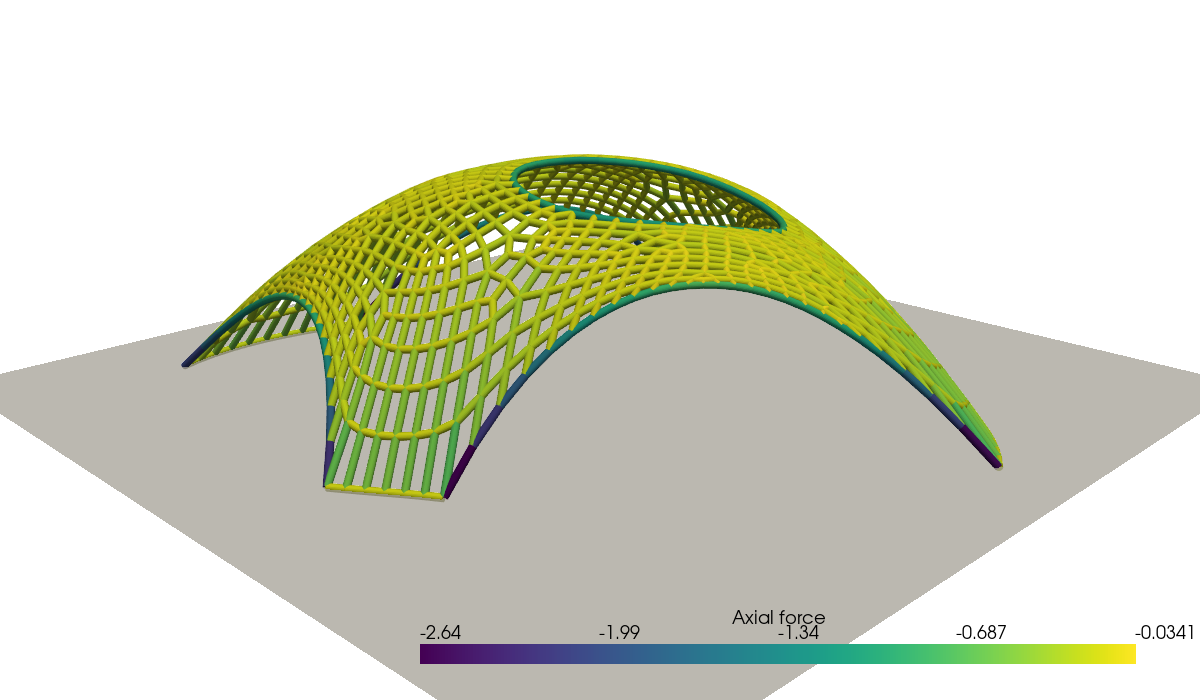

In [9]:
N = fem.Function(Q, name="Axial_force")
N.interpolate(fem.Expression(-q * l0 * stretch(X), Q.element.interpolation_points))

positions = X.x.array.reshape(-1, 3).copy()
positions[:, 2] *= -1  # inversion of the hanging model

pyvista.set_jupyter_backend("static")
topology, cell_types, _ = plot.vtk_mesh(V)
grid = pyvista.UnstructuredGrid(topology, cell_types, positions)
grid.cell_data["Axial force"] = N.x.array[Q.dofmap.list[:num_bars, 0]]
bars = grid.extract_surface(algorithm=None).tube(radius=0.04)

plotter = pyvista.Plotter(window_size=(1200, 700))
plotter.add_mesh(
    bars,
    scalars="Axial force",
    cmap="viridis",
)
plotter.add_mesh(pyvista.Plane(i_size=10, j_size=10), color="lightgray", opacity=0.75)
plotter.camera_position = [(9.5, -9.5, 5.0), (0, 0, 0.4), (0, 0, 1)]
plotter.show()

Finally, we compare the plan of the gridshell with the reference layout. The nodes of the shell move inwards: the free edges form arches between the supports, whose depth is controlled by the force density of the edge members, and the oculus shrinks.

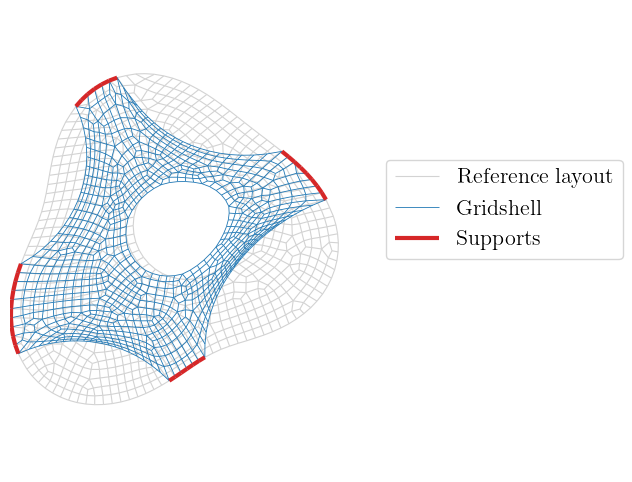

In [10]:
bar_nodes = network.geometry.dofmaps[0][:num_bars]
node_dofs = V.dofmap.list[:num_bars]
fig, ax = plt.subplots(figsize=(9, 6))
ax.add_collection(
    LineCollection(
        network.geometry.x[bar_nodes, :2],
        colors="lightgray",
        lw=0.8,
        label="Reference layout",
    )
)
ax.add_collection(
    LineCollection(positions[node_dofs, :2], colors="C0", lw=0.6, label="Gridshell")
)
supports = network.geometry.x[bar_nodes[bar_tags.find(SUPPORT)], :2]
ax.add_collection(LineCollection(supports, colors="C3", lw=3, label="Supports"))
ax.autoscale()
ax.set_aspect("equal")
ax.axis("off")
ax.legend(bbox_to_anchor=(1.8, 0.7))
plt.show()

```{seealso}
In this tour, the force densities are prescribed and the resulting forces and shape are an output. Many extensions of the method aim at controlling the result, for instance by adjusting the force densities to obtain prescribed bar forces or lengths, or by solving an optimization problem on the force densities, see {cite:p}`veenendaal2012overview,adriaenssens2014shell`.
```

## References

```{bibliography}
:filter: docname in docnames
```